In [1]:
import os
import pandas as pd

DATASET_PATH = r"D:\ARTEN_Enhanced_Dataset_640"

In [2]:
image_extensions = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp"
)

statistics = []

for crop in os.listdir(DATASET_PATH):

    crop_path = os.path.join(
        DATASET_PATH,
        crop
    )

    if not os.path.isdir(crop_path):
        continue

    healthy_count = 0
    diseased_count = 0

    for root, dirs, files in os.walk(crop_path):

        image_count = len([
            f for f in files
            if f.lower().endswith(
                image_extensions
            )
        ])

        if "healthy" in root.lower():

            healthy_count += image_count

        else:

            diseased_count += image_count

    statistics.append([

        crop,
        healthy_count,
        diseased_count,
        healthy_count + diseased_count

    ])

table1 = pd.DataFrame(

    statistics,

    columns=[
        "Crop",
        "Healthy",
        "Diseased",
        "Enhanced Images"
    ]

)

table1

,Crop,Healthy,Diseased,Enhanced Images
0,test,0,2191,2191
1,train,0,15310,15310
2,valid,0,4374,4374


In [3]:
table1.to_csv(
    "Table1_ARTEN_Dataset_Composition.csv",
    index=False
)

table1

,Crop,Healthy,Diseased,Enhanced Images
0,test,0,2191,2191
1,train,0,15310,15310
2,valid,0,4374,4374


In [4]:
table2 = pd.DataFrame({

    "Attribute":[

        "Dataset Name",
        "Total Images",
        "Crop Categories",
        "Image Resolution",
        "Enhancement Framework",
        "Training Epochs",
        "Output Dataset"

    ],

    "Value":[

        "ARTEN-Enhanced Multi-Crop Disease Dataset",
        "21875",
        "4",
        "640 × 640",
        "ARTEN",
        "100",
        "21875 Enhanced Images"

    ]

})

table2

,Attribute,Value
0,Dataset Name,ARTEN-Enhanced Multi-Crop Disease Dataset
1,Total Images,21875
2,Crop Categories,4
3,Image Resolution,640 × 640
4,Enhancement Framework,ARTEN
5,Training Epochs,100
6,Output Dataset,21875 Enhanced Images


In [5]:
table2.to_csv(
    "Table2_ARTEN_Characteristics.csv",
    index=False
)

table2

,Attribute,Value
0,Dataset Name,ARTEN-Enhanced Multi-Crop Disease Dataset
1,Total Images,21875
2,Crop Categories,4
3,Image Resolution,640 × 640
4,Enhancement Framework,ARTEN
5,Training Epochs,100
6,Output Dataset,21875 Enhanced Images


In [6]:
table3 = pd.DataFrame({

    "Metric":[

        "Average PSNR (dB)",
        "Average SSIM",
        "Average Clarity Improvement (%)"

    ],

    "Value":[

        37.98,
        0.9768,
        110.33

    ]

})

table3

,Metric,Value
0,Average PSNR (dB),37.9800
1,Average SSIM,0.9768
2,Average Clarity Improvement (%),110.3300


In [7]:
table3.to_csv(
    "Table3_ARTEN_Performance.csv",
    index=False
)

table3

,Metric,Value
0,Average PSNR (dB),37.9800
1,Average SSIM,0.9768
2,Average Clarity Improvement (%),110.3300


In [8]:
import cv2
import random
import matplotlib.pyplot as plt
import numpy as np

In [9]:
ORIGINAL_ROOT = DATASET_PATH

ENHANCED_ROOT = r"D:\ARTEN_Enhanced_Dataset_640"

In [10]:
pairs = []

for root, dirs, files in os.walk(
    ORIGINAL_ROOT
):

    for file in files:

        if file.lower().endswith(
            ('.jpg','.jpeg','.png','.bmp')
        ):

            orig_path = os.path.join(
                root,
                file
            )

            relative = os.path.relpath(
                orig_path,
                ORIGINAL_ROOT
            )

            enh_path = os.path.join(
                ENHANCED_ROOT,
                relative
            )

            if os.path.exists(
                enh_path
            ):

                pairs.append(
                    (
                        orig_path,
                        enh_path
                    )
                )

print(len(pairs))

21875


IndexError: index 4 is out of bounds for axis 0 with size 4

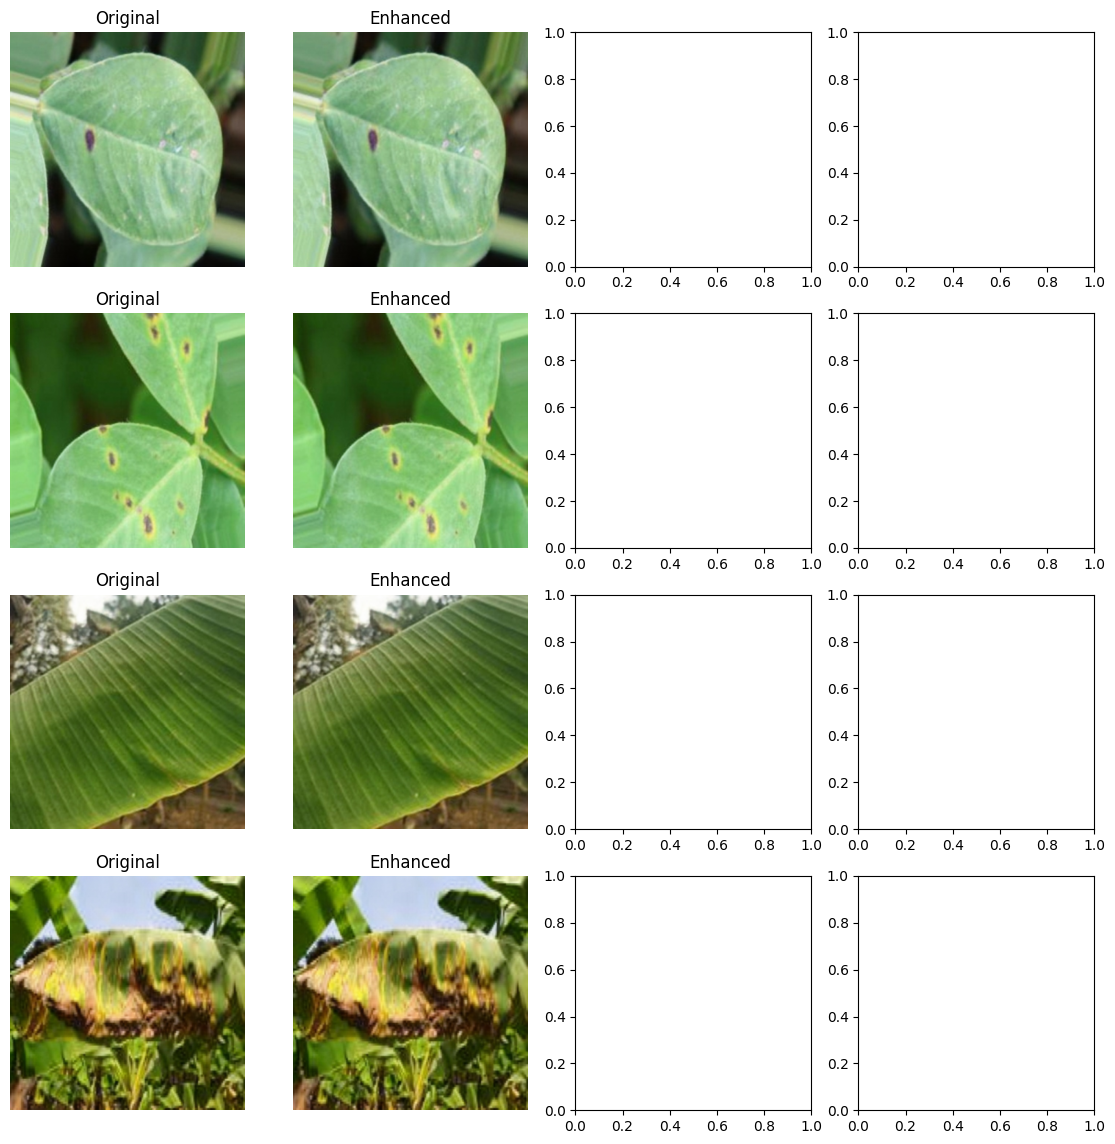

In [11]:
fig, axes = plt.subplots(
    4,
    4,
    figsize=(14,14)
)

selected = random.sample(
    pairs,
    8
)

for idx, (orig_path, enh_path) in enumerate(selected):

    orig = cv2.cvtColor(
        cv2.imread(orig_path),
        cv2.COLOR_BGR2RGB
    )

    enh = cv2.cvtColor(
        cv2.imread(enh_path),
        cv2.COLOR_BGR2RGB
    )

    axes[idx,0].imshow(orig)
    axes[idx,0].set_title("Original")
    axes[idx,0].axis("off")

    axes[idx,1].imshow(enh)
    axes[idx,1].set_title("Enhanced")
    axes[idx,1].axis("off")

plt.tight_layout()

plt.savefig(
    "Figure2_Visual_Comparison.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

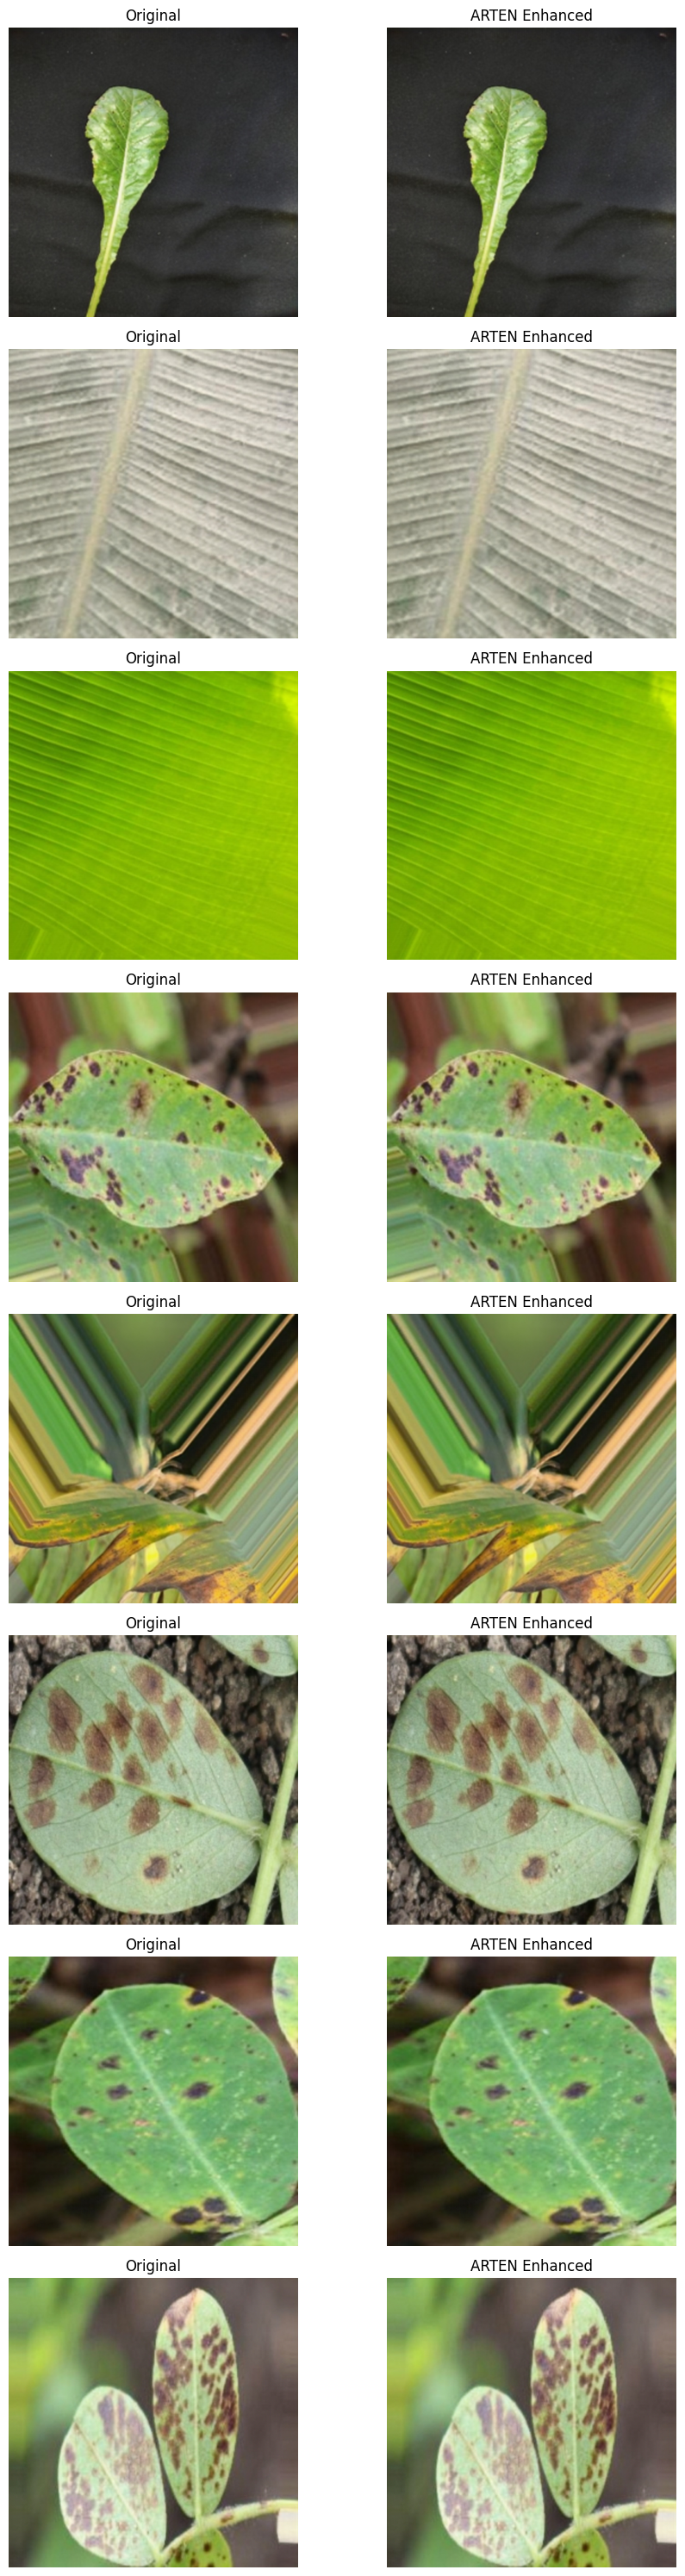

In [13]:
fig, axes = plt.subplots(
    8,
    2,
    figsize=(10,30)
)

selected = random.sample(
    pairs,
    8
)

for idx, (orig_path, enh_path) in enumerate(selected):

    orig = cv2.cvtColor(
        cv2.imread(orig_path),
        cv2.COLOR_BGR2RGB
    )

    enh = cv2.cvtColor(
        cv2.imread(enh_path),
        cv2.COLOR_BGR2RGB
    )

    axes[idx,0].imshow(orig)
    axes[idx,0].set_title("Original")
    axes[idx,0].axis("off")

    axes[idx,1].imshow(enh)
    axes[idx,1].set_title("ARTEN Enhanced")
    axes[idx,1].axis("off")

plt.tight_layout()

plt.savefig(
    "Figure2_Visual_Comparison.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

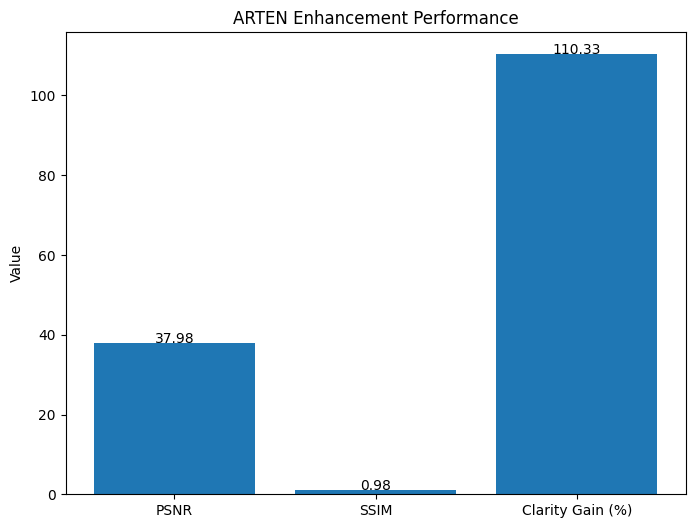

In [14]:
import matplotlib.pyplot as plt

metrics = [
    37.98,
    0.9768,
    110.33
]

labels = [
    "PSNR",
    "SSIM",
    "Clarity Gain (%)"
]

plt.figure(figsize=(8,6))

bars = plt.bar(
    labels,
    metrics
)

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        height,
        f"{height:.2f}",
        ha="center"
    )

plt.ylabel("Value")

plt.title(
    "ARTEN Enhancement Performance"
)

plt.savefig(
    "Figure4_Evaluation.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()